In [1]:
import sys
sys.path.append('../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp

# Constant BC

In [2]:
# input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/simulation_'
input_folder = '../output/Simulations_Paper/Constant/runoff/'

In [3]:
constant_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

constant_dbs = {}
for parametrization, filename in constant_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        constant_dbs[parametrization] = pickle.load(pickle_file)


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [4]:
for idx,parametrization in enumerate(constant_dbs):
    print(parametrization)
    theta_i_total = constant_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print(jnp.round(id_max/12), max_theta_i)
    print(jnp.round(id_av_max/12), av_max)
    print(i/12,av_max_i)
    print(i/12,jnp.max(theta_i_total[-1]))

drying
59.0 0.17851734
83.0 0.09114443
150.0 1e-04
150.0 0.0057834447
drying_omega10
79.0 0.16572271
81.0 0.08142801
150.0 1e-04
150.0 1e-04
permaFoam_omega10
82.0 0.17256686
82.0 0.100996874
150.0 1e-04
150.0 0.031295784
permaFoam_omega50
80.0 0.16138309
83.0 0.068129174
150.0 1e-04
150.0 1e-04
cap
54.0 0.38499352
92.0 0.12806061
150.0 0.00761086
150.0 0.13851202


KeyboardInterrupt: 

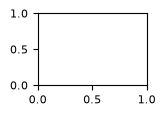

In [5]:
index = 12*120
cm = 1/2.54  # centimeters in inches
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=True)
fig.savefig(f"../figures/Simulations_Paper/Constant/constant_{index//12}d_streamlines_cum.png", dpi=600, bbox_inches="tight")

## Temperature distribution     

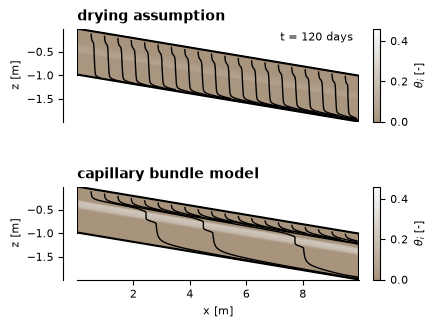

In [ ]:
index = 120*12
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, parametrisations=["drying","cap"], slope=-0.1,figsize=(10*cm,7*cm),cum=False)
fig.savefig(f"../figures/Simulations_Paper/Constant/graphicalAbstract_{index//12}d.png", dpi=600, bbox_inches="tight")

In [ ]:
fig, axes = plotting_utils.plot_T_grid(constant_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../figures/Simulations_Paper/Constant/constant_{index//12}d_T.png", dpi=600, bbox_inches="tight")

## Forcing comparison: ERA5 vs. constant-BC ramp

Shows the real ERA5-Land forcing used for the `simulation` segment (post-spinup, i.e. what the constant-BC run stands in for) next to the smoothed tanh cooling/warming ramp used in the constant-BC runoff test. Axes are independent (not shared): the ERA5 recharge peaks and temperature range are 2-3 orders of magnitude larger/wider than the idealized ramp, so a shared scale would flatten the ramp panel to an invisible line. The point of the figure is to show the *character* (spiky/eventful vs. smooth/idealized) of each forcing, not to overlay them at matching magnitude.

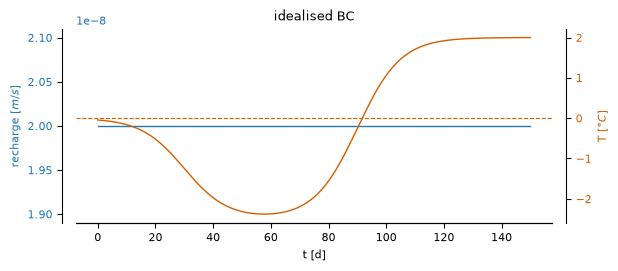

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- constant-BC tanh ramp forcing (same formula as Constant_*.ipynb cell 04c2d77c) ---
T_cold, T_warm = -2.5, 2.0
t1, w1 = 30.0, 15.0   # cooling transition centered day 30, ~30 d wide
t2, w2 = 90.0, 15.0   # warming transition centered day 90, ~30 d wide
t_const = np.linspace(0, 150, 1000)
s_cool = 0.5 * (1 + np.tanh((t_const - t1) / w1))
s_warm = 0.5 * (1 + np.tanh((t_const - t2) / w2))
T_const = 0.0 + (T_cold - 0.0) * s_cool + (T_warm - T_cold) * s_warm
q_const = 2e-8 * np.ones_like(t_const)

cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(1, figsize=(16*cm, 7*cm))

ax.set_title("idealised BC")
ax.plot(t_const, q_const, color='tab:blue', linewidth=1)
ax.set_ylabel('recharge $[m/s]$', color='tab:blue')
ax.tick_params(axis='y', labelcolor='tab:blue')
ax.set_xlabel('t [d]')
ax.spines[['top','right']].set_visible(False)

ax_cp = ax.twinx()
ax_cp.plot(t_const, T_const, color="#D55E00", linewidth=1)
ax_cp.set_ylabel('T $[°C]$', color="#D55E00")
ax_cp.tick_params(axis='y', labelcolor="#D55E00")
ax_cp.axhline(0, color="#D55E00", linestyle='--', linewidth=0.8)
ax_cp.spines[['top','left']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

fig.tight_layout()
fig.savefig("../figures/Simulations_Paper/Constant/forcing_comparison.png", dpi=600)

# ERA5-Land BC Simulation

In [ ]:
input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/tl1/simulation_'
# input_folder = '../output/Simulations_Paper/Constant/Interpolation/'

In [ ]:
era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


In [ ]:
for idx,parametrization in enumerate(era5_dbs):
    print(parametrization)
    theta_i_total = era5_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print(jnp.round(id_max/12), max_theta_i)
    print(jnp.round(id_av_max/12), av_max)
    print(i,av_max_i)
    print(i,jnp.max(theta_i_total[-1]))

drying
15.0 0.21039249
15.0 0.14630309
212 1e-04
212 1e-04
drying_omega10
14.0 0.1590376
16.0 0.108092636
212 1e-04
212 1e-04
permaFoam_omega10
14.0 0.20064142
15.0 0.12952133
212 1e-04
212 1e-04
permaFoam_omega50
15.0 0.1569909
15.0 0.07131138
212 1e-04
212 1e-04
cap
0.0 0.38499257
16.0 0.18546878
212 1e-04
212 0.0055742273


## Cumulative partitioning comparison across parametrizations

values at the end of the simulation for drying
surf 3.0916328
values at the end of the simulation for drying_omega10
surf 3.3413718
values at the end of the simulation for permaFoam_omega10
surf 2.9028938
values at the end of the simulation for permaFoam_omega50
surf 3.0818048
values at the end of the simulation for cap
surf 3.4055026
values at the end of the simulation for drying
top 0.28150174
values at the end of the simulation for drying_omega10
top 0.1375912
values at the end of the simulation for permaFoam_omega10
top 0.2181527
values at the end of the simulation for permaFoam_omega50
top 0.13430806
values at the end of the simulation for cap
top 0.1591316
values at the end of the simulation for drying
bottom 0.16101731
values at the end of the simulation for drying_omega10
bottom 0.054888666
values at the end of the simulation for permaFoam_omega10
bottom 0.42994094
values at the end of the simulation for permaFoam_omega50
bottom 0.053717583
values at the end of the simulation f

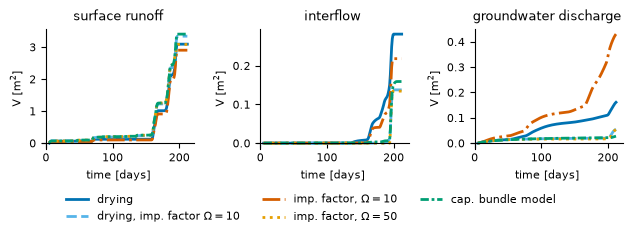

In [ ]:
fig, axes = plotting_utils.plot_cumulative_partitioning_grid(era5_dbs, relative=False)
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_cum.png", dpi=600)

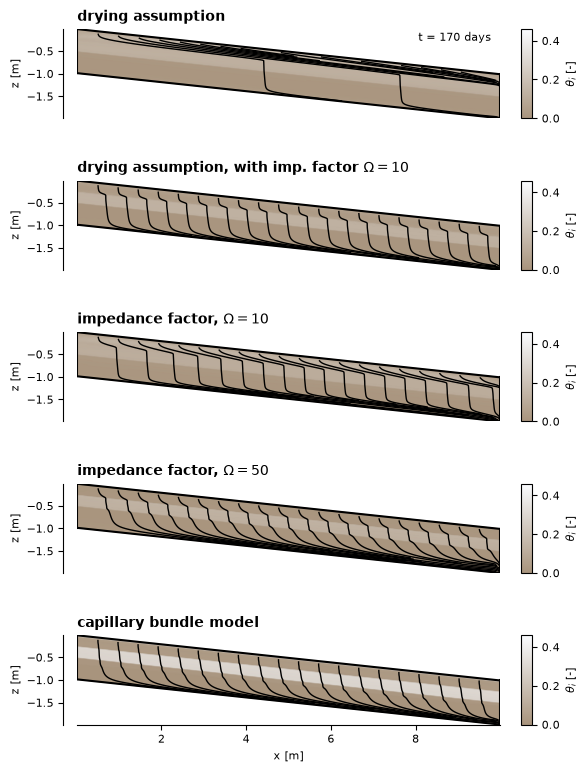

In [ ]:
index = 170
fig, axes = plotting_utils.plot_streamlines_grid(era5_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=False)
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_{index}.png",dpi=600)

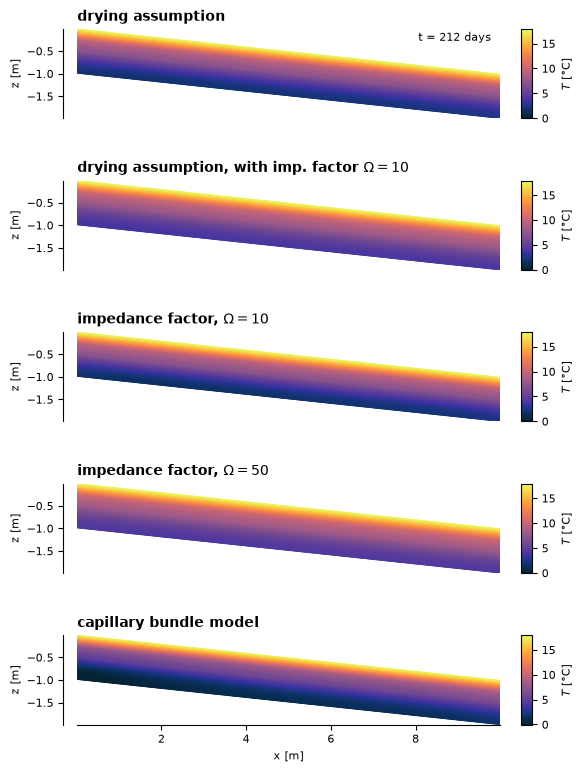

In [ ]:
index = -1
fig, axes = plotting_utils.plot_T_grid(era5_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_{index}d_T.png",dpi=600)

# Mechanism: capillary barrier vs. ice lens

In [ ]:
# for parametrization, db in era5_dbs.items():
#     fig, axes = plotting_utils.plot_Ku(db, parametrization, [7, 71, 165],
#                                        interp_folder="../input/interpolation/",
#                                        suptitle=plotting_utils.parametrization_label(parametrization))
#     # fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/Ku_{parametrization}.png", dpi=300)
